PROVA 3

parametri

Attività 1: costruzione della covarianza

[[ 0.000324  -0.0005265  0.         0.       ]
 [-0.0005265  0.002025   0.         0.       ]
 [ 0.         0.         0.0004     0.       ]
 [ 0.         0.         0.         0.0001   ]]

La matrice è simmetrica? True

La diagonale è positiva? True

Gli autovalori sono non negativi? True


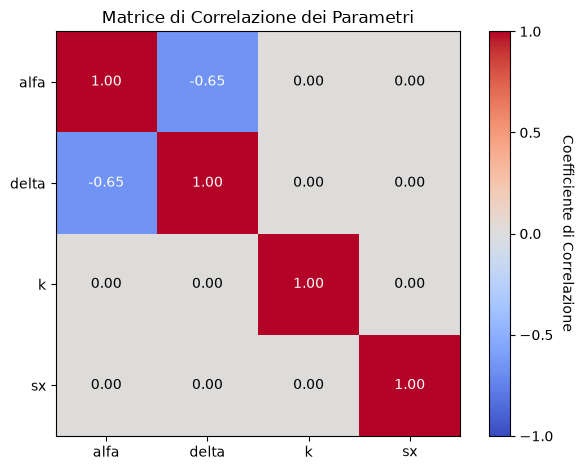


La matrice è simmetrica? True

La diagonale è positiva? True

Gli autovalori sono non negativi? True


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import math
from scipy import stats
from scipy.linalg import block_diag

alfa = 0.910 #mm^(-1)
u_alfa = 0.018 #mm^(-1)
delta = 5.180 #mm^(-1)
u_delta = 0.045 #mm^(-1)
k = 1.000
u_k = 0.020
sx = 1.000
u_sx = 0.010

rho = -0.65 

z = np.array([alfa, delta, k, sx])
u_z = np.array([u_alfa, u_delta, u_k, u_sx])

cov_ad = rho * u_alfa * u_delta 
#costruzione del blocco di covarianza del fit (C_ad)
C_ad = np.array(
   [ [u_alfa**2 , cov_ad],
    [cov_ad , u_delta**2]   
   ]       
) 
#costruzione del blocco di covarianza tra k e sx  
C_ksx = np.diag( [u_k**2, u_sx**2]) #è diagonale perché k e sx sono indipendenti tra loro 

C_z = block_diag(C_ad, C_ksx) #matrice di covarianza 4X4
print (C_z)

#verifica delle proprietà di C_z

simmetria = np.allclose(C_z, C_z.T)  
print(f"\nLa matrice è simmetrica? {simmetria}") 

diagonale_positiva = np.all(np.diag(C_z)>0)
print(f"\nLa diagonale è positiva? {diagonale_positiva}") 

autovalori = np.linalg.eigvalsh(C_z)
autovalori_non_negativi = np.all(autovalori>=0)
print(f"\nGli autovalori sono non negativi? {autovalori_non_negativi}")


#mappa di colore

Cerr = np.sqrt(np.diag(C_z))
corr_matrix = C_z/np.outer(Cerr,Cerr) #costruzione della matrice di correlazione

fig, ax = plt.subplots()
cax = ax.imshow(corr_matrix, cmap='coolwarm', vmin=-1, vmax= 1)
cbar = fig.colorbar(cax, ticks=[-1,-0.5,0,0.5,1])
cbar.set_label('Coefficiente di Correlazione', rotation=270, labelpad=15)

parametri_nome = ["alfa", "delta", "k", "sx"]
ax.set_xticks(range(len(parametri_nome)))
ax.set_yticks(range(len(parametri_nome)))
ax.set_xticklabels(parametri_nome)
ax.set_yticklabels(parametri_nome)

for i in range(len(parametri_nome)):
    for j in range(len(parametri_nome)):
        ax.text(j,i,f"{corr_matrix[i,j]:.2f}",
            ha="center", va="center",
            color = "black" if abs(corr_matrix[i,j])<0.6 else "white")

ax.set_title("Matrice di Correlazione dei Parametri")
plt.tight_layout()
plt.show()  

#verifichiamo che la matrice di correlazione sia simmetrica e con diagonale positiva
simmetria = np.allclose(corr_matrix, corr_matrix.T)
print(f"\nLa matrice è simmetrica? {simmetria}")

diagonale_positiva = np.all(np.diag(corr_matrix)>0)
print(f"\nLa diagonale è positiva? {diagonale_positiva}")

#questo non basta per garantire che la matrice sia valida. Verifichiamo che i valori degli autovalori siano non negativi.
autovalori = np.linalg.eigvalsh(corr_matrix)
autovalori_non_negativi = np.all(autovalori>=0)
print(f"\nGli autovalori sono non negativi? {autovalori_non_negativi}")


PROVA 2: PROPAGAZIONE ANALITICA

In [35]:
a = alfa / (k*sx) #(mm)
d = delta / (k*sx) #(mm)
q = delta / alfa #adimensionale
g_z = np.array([a, d, q])

#costruzione del jacobiano 
J = np.array([
        [1/(k*sx), 0,        -alfa/(k**2*sx), -alfa/(k*sx**2)],
        [0,        1/(k*sx), -delta/(k**2*sx), -delta/(k*sx**2)],
        [-delta/alfa**2, 1/alfa,     0,             0           ],
    ])
#propagazione lineare
C_g = J @ C_z @ J.T
print(C_g)

#valori diagonali, incertezze marginali 
print(f"\nI valori centrali sono {np.diag(C_g)}")

Cov = np.sqrt(np.diag(C_g))
print(f"\nLe incertezze marginali u(a) e u(d) = ({Cov}) mm ")

#matrice di correlazione di a,d e q
corr_matrix_g = C_g/np.outer(Cov,Cov)
print(f"\n La matrice di correlazione è \n {corr_matrix_g}")

#verifichiamo (aggiungere)
blocco2 = (u_delta/delta)**2 + (u_alfa/alfa)**2 - 2*C_z[0, 1]/(alfa*delta)
u_q = q * np.sqrt(blocco2)
assert np.isclose(u_q, Cov[2])

[[ 0.00073805  0.0018304  -0.00260528]
 [ 0.0018304   0.0154412   0.00551868]
 [-0.00260528  0.00551868  0.02236127]]

I valori centrali sono [0.00073805 0.0154412  0.02236127]

Le incertezze marginali u(a) e u(d) = ([0.02716708 0.12426263 0.14953685]) mm 

 La matrice di correlazione è 
 [[ 1.          0.54220384 -0.64130381]
 [ 0.54220384  1.          0.29699324]
 [-0.64130381  0.29699324  1.        ]]


PROVA 3: PROPAGAZIONE MONTE CARLO CORRELATA

[[0.90941923 5.22638418 5.74694705]
 [0.94568266 5.18160035 5.47921685]
 [0.90798329 5.20615476 5.73375615]
 ...
 [0.93984521 5.22284683 5.55713512]
 [0.8990673  5.29910977 5.8940079 ]
 [0.90028289 5.11380584 5.68022104]]
True
{'a': {'media': np.float64(0.9100192706020498), 'deviazione': np.float64(0.017995005211456545), 'mediana': np.float64(0.9100053618236055), 'p16': np.float64(0.8921147678966422), 'p84': np.float64(0.9279398283978877)}, 'd': {'media': np.float64(5.179877932972348), 'deviazione': np.float64(0.04498653337114771), 'mediana': np.float64(5.179926980267931), 'p16': np.float64(5.135107881959925), 'p84': np.float64(5.224505837804346)}, 'q': {'media': np.float64(0.9999821894884328), 'deviazione': np.float64(0.02000899168006262), 'mediana': np.float64(1.0000240083978413), 'p16': np.float64(0.9800096047405348), 'p84': np.float64(1.0199578235025688)}}


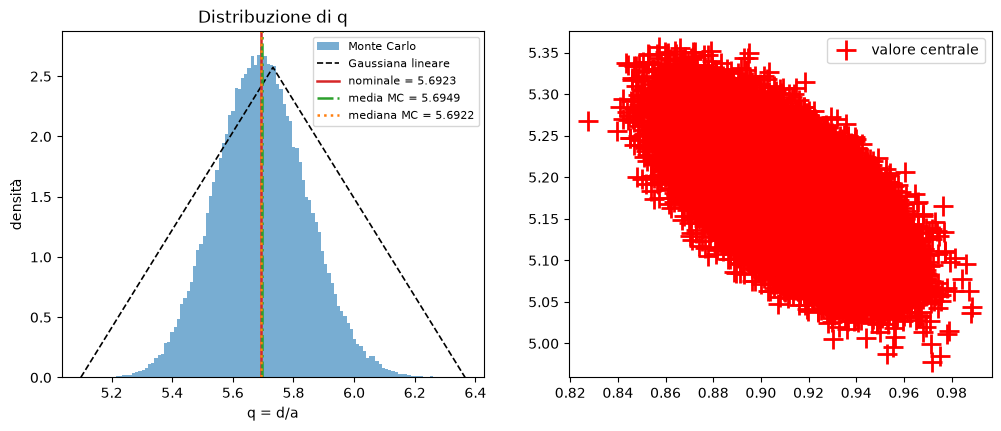

In [ ]:

#generazione del campione
M = 100_000
rng = np.random.default_rng(20261003)
campioni = rng.multivariate_normal(
 mean=z,
 cov=C_z,
 size=M
)

#calcolo delle grandezze 
def calcola_grandezze(campioni) :
   alfa_mc = campioni[:,0]
   delta_mc = campioni[:,1]
   k_mc = campioni[:,2]
   sx_mc = campioni[:,3]
   #grandezze derivate:
   a_mc = alfa_mc/(k_mc*sx_mc)
   d_mc = delta_mc/(k_mc*sx_mc)
   q_mc = delta_mc/alfa_mc   

   return np.column_stack((a_mc, d_mc, q_mc))
val = calcola_grandezze(campioni)
print(val)

#controllo dell'ammissibilità fisica
print(np.all(campioni > 0))     

#calcolo delle statistiche delle distribuzioni
def calcola_statistica(campioni):
    nomi = ["a", "d", "q"]
    risultati = {}
    for i, nome in enumerate(nomi):
        valori=campioni[:,i]
        media = np.mean(valori)
        std_dev = np.std(valori,ddof=1)
        mediana = np.median(valori)
        p16,p84 = np.percentile(valori, [16,84])
        risultati[nome] = {
            "media": media,
            "deviazione": std_dev,
            "mediana": mediana,
            "p16": p16,
            "p84": p84
            }
    return risultati

stat = calcola_statistica(campioni)
print (stat)

#istogramma di q (controllare gaussiana, secondo me potremmo snellire un po')
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].hist(q_mc, bins=120, density=True, alpha=0.6, label="Monte Carlo")
xs = np.linspace(q_mc.min(), q_mc.max(), 3)
uq = Cov[2]
ax[0].plot(xs, np.exp(-0.5*((xs - q)/uq)**2)/(uq*np.sqrt(2*np.pi)),
           "k--", lw=1.2, label="Gaussiana lineare")
ax[0].axvline(q, color="C3", lw=1.8, label=f"nominale = {q:.4f}")
ax[0].axvline(q_mc.mean(),  color="C2", lw=1.8, ls="-.", label=f"media MC = {q_mc.mean():.4f}")
ax[0].axvline(np.median(q_mc), color="C1", lw=1.8, ls=":", label=f"mediana MC = {np.median(q_mc):.4f}")
ax[0].set_xlabel("q = d/a"); ax[0].set_ylabel("densità"); ax[0].set_title("Distribuzione di q")
ax[0].legend(fontsize=8)

#scatter plot nel piano (alfa, delta)
idx = np.random.default_rng(1).choice(M, 3000, replace=False)
ax[1].scatter(campioni[idx, 0], campioni[idx, 1], s=4, alpha=0.4)
ax[1].plot(alfa_mc, delta_mc, "r+", ms=14, mew=2, label="valore centrale")
#ax[1].set_xlabel(r"$\ alfa_mc$ [mm$^{-1}$]"); ax[1].set_ylabel(r"$\delta_mc$ [mm$^{-1}$]")
#ax[1].set_title(fr"Campioni nel piano ($\alfa_mc$,$\delta_mc$), $\rho$ = {np.corrcoef(campioni[:,0], campioni[:,1])[0,1]:.2f}")
ax[1].legend()
plt.show()
 

PROVA 4: EFFETTO DELLE CORRELAZIONI

In [ ]:
import pandas as pd #per la tabella di confronto

rho_0 = 0

#1. Calcolo analitico
C_ad_0= np.array(
   [ [u_alfa**2 , 0],
    [ 0 , u_delta**2]   
   ]       
)
C_z_0 = block_diag(C_ad_0, C_ksx)
print (C_z_0) #verifico che la matrice sia diagonale
corr_matrix_0 = C_z_0/np.outer(Cerr,Cerr)
C_g_0 = J @ C_z_0 @ J.T

Cov_0 = np.sqrt(np.diag(C_g_0)) #gli elementi diagonali di Cov_0 sono uguali a quelli di Cov, quindi le incertezze marginali non cambiano

corr_matrix_g_0 = C_g_0/np.outer(Cov_0,Cov_0)
blocco2_0 = (u_delta/delta)**2 + (u_alfa/alfa)**2  
u_q_0 = q * np.sqrt(blocco2_0)
assert np.isclose(u_q_0, Cov_0[2])

#2. Monte Carlo
campioni_0 = rng.multivariate_normal(
 mean=z,
 cov=C_z_0,
 size=M
)

val_0 = calcola_grandezze(campioni_0) 
stat_0 = calcola_statistica(campioni_0)

#tabella di confronto

confronto = pd.DataFrame(
    [
        [Cov[0],Cov[1],Cov[2],
         Cov_0[0], Cov_0[1], Cov_0[2],
         *((Cov_0 - Cov) / Cov *100)],
        [stat["a"]["deviazione"], stat["d"]["deviazione"], stat["q"]["deviazione"],
         stat_0["a"]["deviazione"], stat_0["d"]["deviazione"], stat_0["q"]["deviazione"],
        *[
            (stat_0[n]["deviazione"]/stat[n]["deviazione"]-1)*100
            for n in ["a","d","q"]
        ]]
    ],
    index=["Analitico", "Monte Carlo"],
    columns=pd.MultiIndex.from_product([
        ["Con correlazione", "Senza correlazione", "Variazione (%)"],
        ["a", "d","q"]
    ])
)

print(confronto) #l'incertezza di q diminuisce se la correlazione tra alfa e delta è nulla
                 #le incertezze marginali rimangono invariate


#grafico della distribuzione di q (la grandezza che risente maggiormente della correlazione)







[[0.000324 0.       0.       0.      ]
 [0.       0.002025 0.       0.      ]
 [0.       0.       0.0004   0.      ]
 [0.       0.       0.       0.0001  ]]
            Con correlazione                     Senza correlazione            \
                           a         d         q                  a         d   
Analitico           0.027167  0.124263  0.149537           0.027167  0.124263   
Monte Carlo         0.017995  0.044987  0.020009           0.017992  0.044951   

                      Variazione (%)                       
                    q              a         d          q  
Analitico    0.122976       0.000000  0.000000 -17.762304  
Monte Carlo  0.020021      -0.018171 -0.079472   0.059735  
